# 03 · Leaf Disease Identification (supporting component)

**Role in the project.** The main product answers *"given a crop, a place and a season, how likely is a good yield?"*
(notebooks 01–02). This notebook builds the **supporting** component: a CNN that looks at a leaf photo and
names the disease. In notebook 04 its output is fed back into the yield outlook.

**Scope.** Of the 13 crops in the yield model, only **maize** has leaf images in PlantVillage, so the CNN is trained on
the four PlantVillage corn classes: *Gray leaf spot*, *Common rust*, *Northern leaf blight* and *Healthy*.

**Model.** MobileNetV2 (ImageNet pre-trained) + transfer learning, as in the proposal.
**Split.** 80 % train / 20 % test, stratified, fixed seed. **Metrics.** Accuracy, precision, recall, F1, confusion matrix.

In [1]:
import os, json, random, pathlib, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
ROOT = pathlib.Path("..").resolve()
IMG_DIR = ROOT / "data" / "plantvillage_corn"
MODELS = ROOT / "models"; FIG = ROOT / "figures"
MODELS.mkdir(exist_ok=True); FIG.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")

## 1. Dataset: PlantVillage corn (maize) leaves

3852 images; ['Common rust', 'Gray leaf spot', 'Healthy', 'Northern leaf blight']


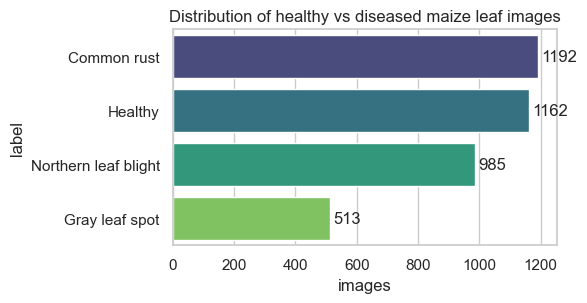

In [2]:
CLASS_DIRS = {
    "Corn_(maize)___healthy": "Healthy",
    "Corn_(maize)___Common_rust_": "Common rust",
    "Corn_(maize)___Northern_Leaf_Blight": "Northern leaf blight",
    "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot": "Gray leaf spot",
}
rows = []
for d, label in CLASS_DIRS.items():
    for f in (IMG_DIR / d).glob("*"):
        if f.suffix.lower() in {".jpg", ".jpeg", ".png"}:
            rows.append((str(f), label))
df = pd.DataFrame(rows, columns=["path", "label"])
class_names = sorted(df.label.unique())
print(len(df), "images;", class_names)

counts = df.label.value_counts()
fig, ax = plt.subplots(figsize=(6, 3.2))
sns.barplot(x=counts.values, y=counts.index, palette="viridis", ax=ax)
ax.set_title("Distribution of healthy vs diseased maize leaf images"); ax.set_xlabel("images")
for i, v in enumerate(counts.values): ax.text(v + 10, i, str(v), va="center")
plt.tight_layout(); plt.savefig(FIG / "disease_class_distribution.png", dpi=150); plt.show()

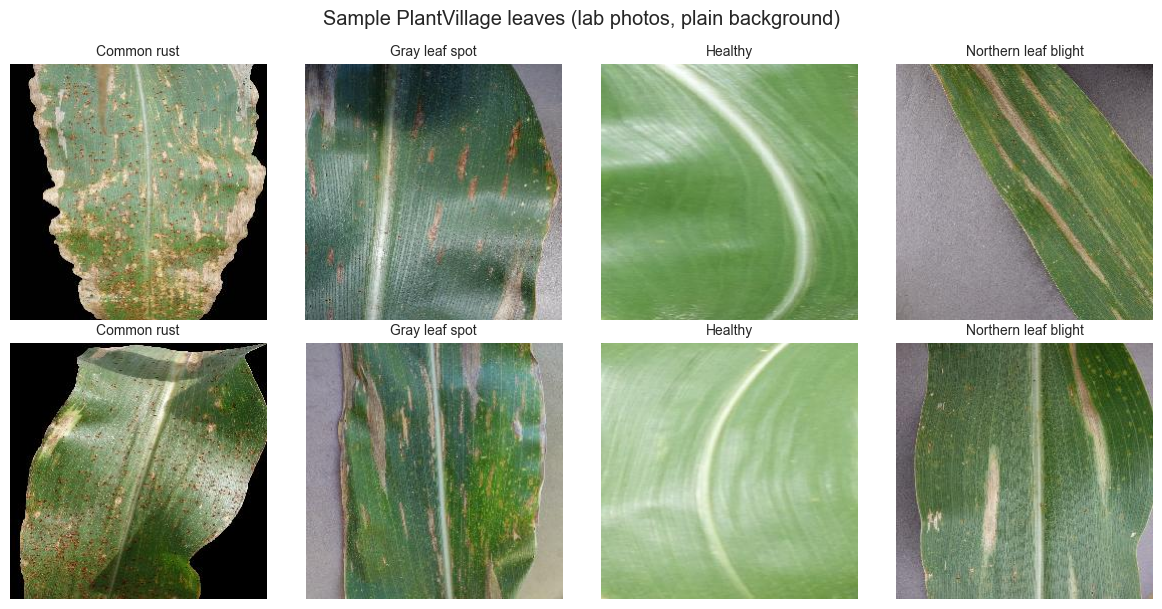

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6.2))
for ax, (lbl, grp) in zip(axes.T, df.groupby("label")):
    for a, p in zip(ax, grp.sample(2, random_state=1).path):
        a.imshow(keras.utils.load_img(p)); a.set_title(lbl, fontsize=10); a.axis("off")
plt.suptitle("Sample PlantVillage leaves (lab photos, plain background)"); plt.tight_layout()
plt.savefig(FIG / "disease_samples.png", dpi=130); plt.show()

## 2. Train / test split (80 / 20, stratified)
Test images are never used for training or for tuning, which avoids data leakage.

**Caveat to remember:** PlantVillage contains several photos of the *same* leaf. A random split can put near-duplicates on
both sides, so test accuracy here is optimistic compared with leaves from a real field.

In [4]:
train_df, test_df = train_test_split(df, test_size=0.20, stratify=df.label, random_state=SEED)
train_df, val_df = train_test_split(train_df, test_size=0.15, stratify=train_df.label, random_state=SEED)
print(len(train_df), "train |", len(val_df), "val |", len(test_df), "test")

2618 train | 463 val | 771 test


## 3. Image preprocessing and augmentation
Resize to 224×224, scale to the range MobileNetV2 expects, and augment training images (flip, rotate, zoom, brightness)
so the model copes with the variety of real leaf photos.

In [5]:
IMG = (224, 224); BATCH = 32
cls_idx = {c: i for i, c in enumerate(class_names)}

def load(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, IMG)
    return img, label

def make_ds(d, training):
    ds = tf.data.Dataset.from_tensor_slices((d.path.values, d.label.map(cls_idx).values))
    if training: ds = ds.shuffle(len(d), seed=SEED)
    ds = ds.map(load, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH)
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds, val_ds, test_ds = make_ds(train_df, True), make_ds(val_df, False), make_ds(test_df, False)

augment = keras.Sequential([
    keras.layers.RandomFlip("horizontal_and_vertical"),
    keras.layers.RandomRotation(0.15),
    keras.layers.RandomZoom(0.15),
    keras.layers.RandomBrightness(0.15),
], name="augmentation")

## 4. Model: MobileNetV2 transfer learning
* Stage 1 – freeze the pre-trained base, train only the new classification head.
* Stage 2 – unfreeze the last block of the base and fine-tune with a small learning rate.

In [6]:
base = keras.applications.MobileNetV2(input_shape=IMG + (3,), include_top=False, weights="imagenet")
base.trainable = False

inputs = keras.Input(shape=IMG + (3,))
x = augment(inputs)
x = keras.applications.mobilenet_v2.preprocess_input(x)
x = base(x, training=False)
x = keras.layers.GlobalAveragePooling2D()(x)
x = keras.layers.Dropout(0.3)(x)
outputs = keras.layers.Dense(len(class_names), activation="softmax")(x)
model = keras.Model(inputs, outputs)
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
print(f"trainable params: {sum(np.prod(v.shape) for v in model.trainable_variables):,}")

trainable params: 5,124


In [7]:
cb = [keras.callbacks.EarlyStopping(patience=2, restore_best_weights=True, monitor="val_loss")]
h1 = model.fit(train_ds, validation_data=val_ds, epochs=6, callbacks=cb, verbose=2)

Epoch 1/6


82/82 - 46s - 557ms/step - accuracy: 0.7704 - loss: 0.6084 - val_accuracy: 0.9114 - val_loss: 0.2220


Epoch 2/6


82/82 - 39s - 476ms/step - accuracy: 0.9068 - loss: 0.2379 - val_accuracy: 0.9395 - val_loss: 0.1617


Epoch 3/6


...

82/82 - 35s - 431ms/step - accuracy: 0.9267 - loss: 0.1862 - val_accuracy: 0.9460 - val_loss: 0.1421


Epoch 5/6


82/82 - 34s - 410ms/step - accuracy: 0.9343 - loss: 0.1656 - val_accuracy: 0.9503 - val_loss: 0.1283


Epoch 6/6


82/82 - 34s - 415ms/step - accuracy: 0.9335 - loss: 0.1596 - val_accuracy: 0.9546 - val_loss: 0.1228


In [8]:
base.trainable = True
for layer in base.layers[:-30]:        # keep early layers frozen
    layer.trainable = False
model.compile(optimizer=keras.optimizers.Adam(1e-5), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h2 = model.fit(train_ds, validation_data=val_ds, epochs=4, callbacks=cb, verbose=2)

Epoch 1/4


82/82 - 55s - 672ms/step - accuracy: 0.9064 - loss: 0.2519 - val_accuracy: 0.9568 - val_loss: 0.1162


Epoch 2/4


82/82 - 73s - 888ms/step - accuracy: 0.9225 - loss: 0.2125 - val_accuracy: 0.9568 - val_loss: 0.1197


Epoch 3/4


82/82 - 78s - 957ms/step - accuracy: 0.9316 - loss: 0.1747 - val_accuracy: 0.9590 - val_loss: 0.1194


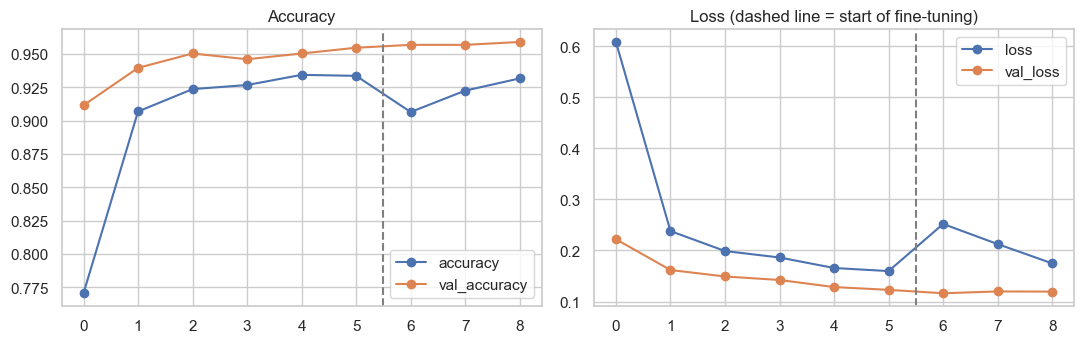

In [9]:
hist = pd.concat([pd.DataFrame(h1.history), pd.DataFrame(h2.history)], ignore_index=True)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
hist[["accuracy", "val_accuracy"]].plot(ax=ax[0], marker="o"); ax[0].set_title("Accuracy"); ax[0].axvline(len(h1.history["loss"]) - .5, ls="--", c="grey")
hist[["loss", "val_loss"]].plot(ax=ax[1], marker="o"); ax[1].set_title("Loss (dashed line = start of fine-tuning)"); ax[1].axvline(len(h1.history["loss"]) - .5, ls="--", c="grey")
plt.tight_layout(); plt.savefig(FIG / "disease_training_curves.png", dpi=150); plt.show()

## 5. Evaluation on the held-out test set

In [10]:
probs = model.predict(test_ds, verbose=0)
y_true = test_df.label.map(cls_idx).values
y_pred = probs.argmax(1)
print(f"Test accuracy: {accuracy_score(y_true, y_pred):.4f}\n")
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

Test accuracy: 0.9390

                      precision    recall  f1-score   support

         Common rust      0.988     1.000     0.994       239
      Gray leaf spot      0.776     0.806     0.790       103
             Healthy      0.987     1.000     0.994       232
Northern leaf blight      0.909     0.863     0.885       197

            accuracy                          0.939       771
           macro avg      0.915     0.917     0.916       771
        weighted avg      0.939     0.939     0.939       771



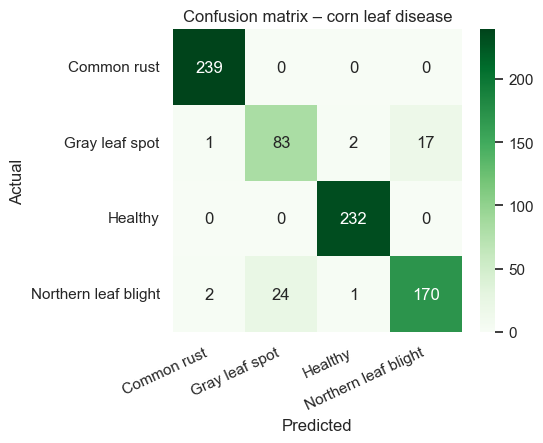

In [11]:
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(5.6, 4.6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", xticklabels=class_names, yticklabels=class_names, ax=ax)
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title("Confusion matrix – corn leaf disease")
plt.xticks(rotation=25, ha="right"); plt.tight_layout(); plt.savefig(FIG / "disease_confusion_matrix.png", dpi=150); plt.show()

## 6. Save the model and a prediction helper
The helper takes a leaf photo and returns the disease class plus a confidence. Notebook 04 re-uses it.

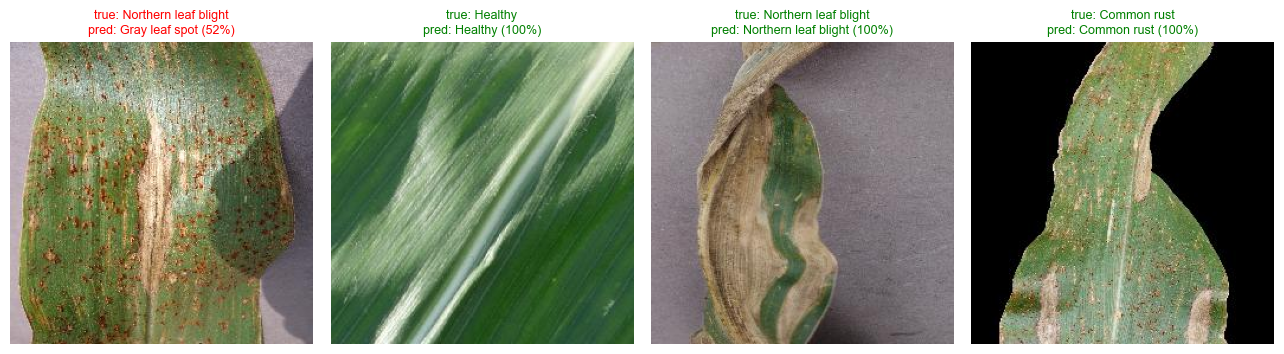

In [12]:
model.save(MODELS / "leaf_disease_mobilenetv2.keras")
json.dump(class_names, open(MODELS / "leaf_disease_classes.json", "w"))
metrics = dict(test_accuracy=float(accuracy_score(y_true, y_pred)), n_test=int(len(y_true)))
json.dump(metrics, open(MODELS / "leaf_disease_metrics.json", "w"))
test_df.assign(pred=[class_names[i] for i in y_pred], conf=probs.max(1)).to_csv(ROOT / "data" / "processed" / "leaf_test_predictions.csv", index=False)

def diagnose_leaf(path):
    img = keras.utils.load_img(path, target_size=IMG)
    p = model.predict(np.expand_dims(keras.utils.img_to_array(img), 0), verbose=0)[0]
    return class_names[int(p.argmax())], float(p.max()), dict(zip(class_names, p.round(3)))

sample = test_df.sample(4, random_state=3)
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6))
for ax, (_, r) in zip(axes, sample.iterrows()):
    lbl, conf, _ = diagnose_leaf(r.path)
    ax.imshow(keras.utils.load_img(r.path)); ax.axis("off")
    ax.set_title(f"true: {r.label}\npred: {lbl} ({conf:.0%})", fontsize=9, color="green" if lbl == r.label else "red")
plt.tight_layout(); plt.savefig(FIG / "disease_sample_predictions.png", dpi=140); plt.show()

## Takeaways
* Transfer learning gets high accuracy on maize leaves with only ~3,800 images and a few minutes of CPU training.
* Treat the number with care: PlantVillage photos are lab-style and near-duplicates may cross the split. Field accuracy will be lower.
* Next (notebook 04): use the detected disease and how many sampled leaves show it to adjust the maize yield outlook.